# IMDB: binary sentiment classification

Experiments with a plain fully connected (dense) network, following the classic Keras examples. Code is unchanged from the original run; only warnings (which contained local file paths) were removed from the saved outputs.

**Experiments:** baseline → ReLU vs. Tanh → MSE vs. cross-entropy loss → number of input words (where applicable) → number of hidden layers → number of neurons.

Results of the number-of-words / layers / neurons experiments are shown as plots only (no numeric summary was printed). Runs are not seeded, so the same configuration gives slightly different numbers in different cells.

**Setup:** 10,000 most frequent words, multi-hot input, Dense(16)-Dense(16)-sigmoid, RMSprop, batch size 512, 20 epochs; validation = first 10,000 training samples; test = 25,000 test reviews.

> **Note on saved outputs:** the outputs of the *ReLU vs. Tanh* and *MSE vs. BCE* cells contain lines such as "Overfitting starts at epoch: …". They come from an earlier version of those cells; the overfitting-detection code is now commented out, so re-running the notebook will not print them. They are kept as saved and should not be treated as results.


ورژن اصلی IMDB

In [1]:
from keras.datasets import imdb
from keras import models
from keras import layers
import numpy as np
from keras import losses
from keras import metrics

# بارگذاری داده‌ها
(train_data, train_labels), (test_data, test_labels) = imdb.load_data(num_words=10000)

# ساخت دیکشنری برای ترجمه ایندکس‌ها به کلمات
word_index = imdb.get_word_index()
reverse_word_index = dict([(value, key) for (key, value) in word_index.items()])
decoded_review = ' '.join([reverse_word_index.get(i - 3, '?') for i in train_data[0]])

# وکتوریزه کردن داده‌ها
def vectorize_sequences(sequences, dimension=10000):
    results = np.zeros((len(sequences), dimension))
    for i, sequence in enumerate(sequences):
        results[i, sequence] = 1.
    return results

X_train = vectorize_sequences(train_data)
X_test = vectorize_sequences(test_data)

# تبدیل لیبل‌ها به نوع داده float32
Y_train = np.asarray(train_labels).astype('float32')
Y_test = np.asarray(test_labels).astype('float32')

# ساخت مدل
model = models.Sequential()
model.add(layers.Dense(16, activation='relu', input_shape=(10000,)))
model.add(layers.Dense(16, activation='relu'))
model.add(layers.Dense(1, activation='sigmoid'))

# کامپایل مدل
model.compile(optimizer="rmsprop",
              loss=losses.binary_crossentropy,
              metrics=[metrics.binary_accuracy])

# تقسیم داده‌ها به مجموعه آموزش و اعتبارسنجی
X_val = X_train[:10000]
partial_X_train = X_train[10000:]
Y_val = Y_train[:10000]
partial_Y_train = Y_train[10000:]

# آموزش مدل
history = model.fit(partial_X_train, partial_Y_train,
                    epochs=20, batch_size=512,
                    validation_data=(X_val, Y_val))

# ارزیابی مدل
results = model.evaluate(X_test, Y_test)
print("Test accuracy:", results[1])


Epoch 1/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - binary_accuracy: 0.7294 - loss: 0.5779 - val_binary_accuracy: 0.8716 - val_loss: 0.3798
Epoch 2/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - binary_accuracy: 0.9037 - loss: 0.3207 - val_binary_accuracy: 0.8831 - val_loss: 0.3112
Epoch 3/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - binary_accuracy: 0.9278 - loss: 0.2356 - val_binary_accuracy: 0.8793 - val_loss: 0.3002
Epoch 4/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - binary_accuracy: 0.9396 - loss: 0.1926 - val_binary_accuracy: 0.8838 - val_loss: 0.2861
Epoch 5/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - binary_accuracy: 0.9487 - loss: 0.1610 - val_binary_accuracy: 0.8828 - val_loss: 0.2906
Epoch 6/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - binary_accuracy: 0.9572 - loss: 0.1375 - val_binary_accuracy: 0.8839 - val_loss: 0.2978
Epoch 7/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - binary_accuracy: 0.9680 - loss: 0.1132 - val_binary_accuracy: 0.8844 - val_loss: 0.3038
Epoch 8/20
30/30 ━━

استفاده از تابع فعال‌سازی tanh به‌جای relu

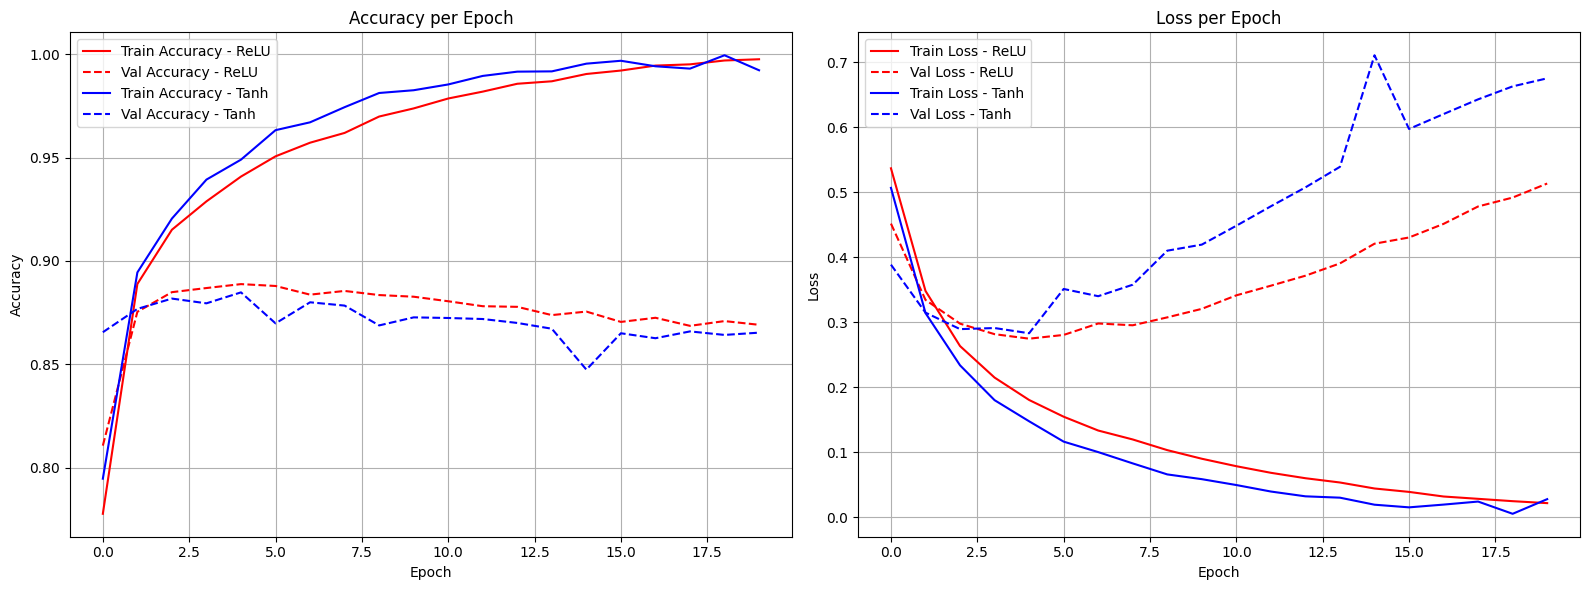

🔍 ReLU:
   Final Test Accuracy: 0.8593
   Final Test Loss: 0.5554
   Overfitting starts at epoch: 9

🔍 Tanh:
   Final Test Accuracy: 0.8553
   Final Test Loss: 0.7333
   Overfitting starts at epoch: 8


In [ ]:
import matplotlib.pyplot as plt
from keras.datasets import imdb
from keras import models, layers
from keras import losses, metrics
import numpy as np

# بارگذاری داده‌ها
(train_data, train_labels), (test_data, test_labels) = imdb.load_data(num_words=10000)

# وکتوریزه کردن داده‌ها با float32
def vectorize_sequences(sequences, dimension=10000):
    results = np.zeros((len(sequences), dimension), dtype='float32')
    for i, sequence in enumerate(sequences):
        results[i, sequence] = 1.
    return results

X_train = vectorize_sequences(train_data)
X_test = vectorize_sequences(test_data)
Y_train = np.asarray(train_labels).astype('float32')
Y_test = np.asarray(test_labels).astype('float32')

# تقسیم داده‌ها
X_val = X_train[:10000]
partial_X_train = X_train[10000:]
Y_val = Y_train[:10000]
partial_Y_train = Y_train[10000:]

# تابع ساخت و آموزش مدل
def build_and_train_model(activation_fn):
    model = models.Sequential([
        layers.Dense(16, activation=activation_fn, input_shape=(10000,)),
        layers.Dense(16, activation=activation_fn),
        layers.Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='rmsprop',
                  loss='binary_crossentropy',
                  metrics=['binary_accuracy'])
    history = model.fit(partial_X_train, partial_Y_train,
                        epochs=20, batch_size=512,
                        validation_data=(X_val, Y_val), verbose=0)
    test_loss, test_acc = model.evaluate(X_test, Y_test, verbose=0)
    return model, history, test_acc, test_loss

# آموزش دو مدل
model_relu, history_relu, acc_relu, loss_relu = build_and_train_model('relu')
model_tanh, history_tanh, acc_tanh, loss_tanh = build_and_train_model('tanh')

# # تابع تشخیص شروع overfitting
# def detect_overfitting_point(history, tolerance=0.01, patience=2):
#     val_losses = history.history['val_loss']
#     train_losses = history.history['loss']
#     for i in range(patience, len(val_losses)):
#         increasing = all(val_losses[j] > val_losses[j - 1] + tolerance for j in range(i - patience + 1, i + 1))
#         if increasing and train_losses[i] < train_losses[i - 1]:
#             return i
#     return None

# overfit_epoch_relu = detect_overfitting_point(history_relu)
# overfit_epoch_tanh = detect_overfitting_point(history_tanh)

# رسم نمودار
plt.figure(figsize=(16, 6))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(history_relu.history['binary_accuracy'], label='Train Accuracy - ReLU', color='red')
plt.plot(history_relu.history['val_binary_accuracy'], label='Val Accuracy - ReLU', linestyle='--', color='red')
plt.plot(history_tanh.history['binary_accuracy'], label='Train Accuracy - Tanh', color='blue')
plt.plot(history_tanh.history['val_binary_accuracy'], label='Val Accuracy - Tanh', linestyle='--', color='blue')
plt.title('Accuracy per Epoch')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Loss
plt.subplot(1, 2, 2)
plt.plot(history_relu.history['loss'], label='Train Loss - ReLU', color='red')
plt.plot(history_relu.history['val_loss'], label='Val Loss - ReLU', linestyle='--', color='red')
plt.plot(history_tanh.history['loss'], label='Train Loss - Tanh', color='blue')
plt.plot(history_tanh.history['val_loss'], label='Val Loss - Tanh', linestyle='--', color='blue')
plt.title('Loss per Epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# نتایج عددی
print("🔍 ReLU:")
print(f"   Final Test Accuracy: {acc_relu:.4f}")
print(f"   Final Test Loss: {loss_relu:.4f}")
# if overfit_epoch_relu is not None:
#     print(f"   Overfitting starts at epoch: {overfit_epoch_relu}")
# else:
#     print("   No clear overfitting detected.")

print("\n🔍 Tanh:")
print(f"   Final Test Accuracy: {acc_tanh:.4f}")
print(f"   Final Test Loss: {loss_tanh:.4f}")
# if overfit_epoch_tanh is not None:
#     print(f"   Overfitting starts at epoch: {overfit_epoch_tanh}")
# else:
#     print("   No clear overfitting detected.")



MSE vs BSE

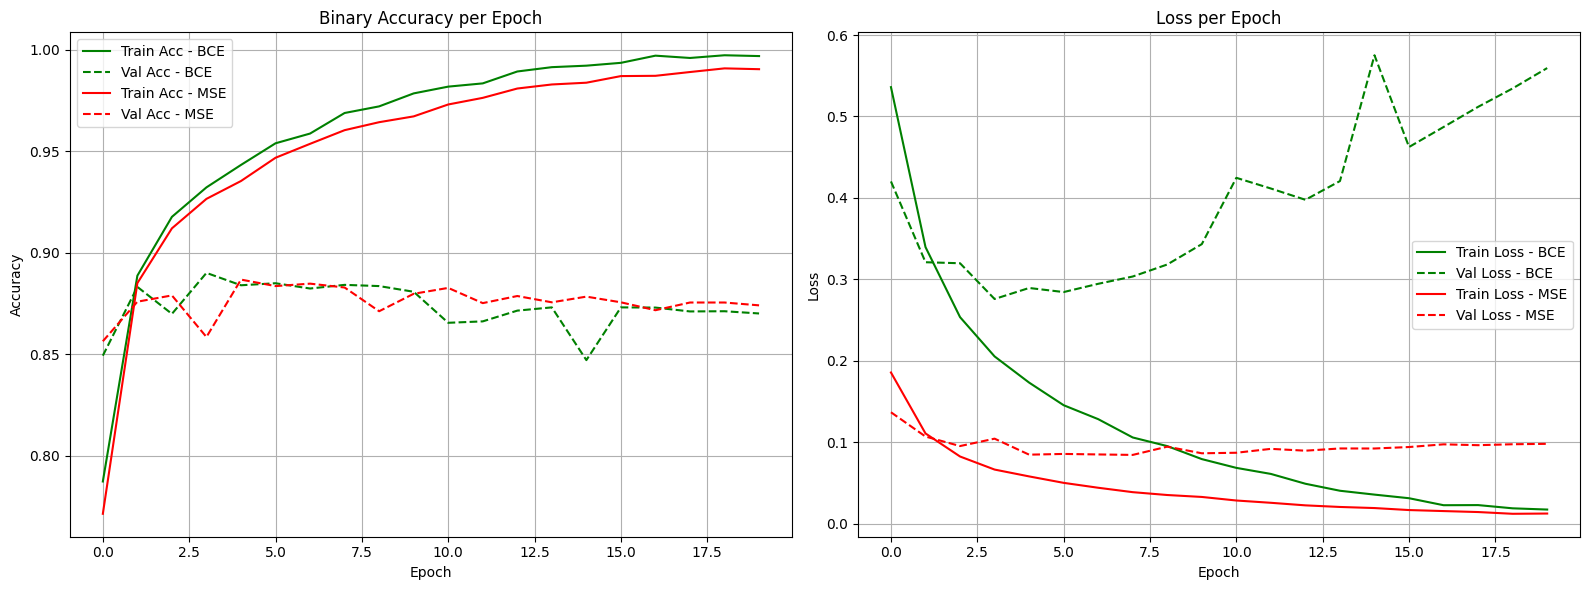

🔍 Binary Crossentropy:
   Final Test Accuracy: 0.8596
   Final Test Loss: 0.5988
   Overfitting starts at epoch: 9

🔍 Mean Squared Error:
   Final Test Accuracy: 0.8626
   Final Test Loss: 0.1061
   No clear overfitting detected.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from keras.datasets import imdb
from keras import models, layers, losses, metrics

# بارگذاری داده‌ها
(train_data, train_labels), (test_data, test_labels) = imdb.load_data(num_words=10000)

# وکتوریزه کردن داده‌ها
def vectorize_sequences(sequences, dimension=10000):
    results = np.zeros((len(sequences), dimension), dtype=np.float32)
    for i, sequence in enumerate(sequences):
        results[i, sequence] = 1.
    return results

X_train = vectorize_sequences(train_data)
X_test = vectorize_sequences(test_data)
Y_train = np.asarray(train_labels).astype('float32')
Y_test = np.asarray(test_labels).astype('float32')

# تقسیم داده‌ها
X_val = X_train[:10000]
partial_X_train = X_train[10000:]
Y_val = Y_train[:10000]
partial_Y_train = Y_train[10000:]

# تابع ساخت مدل با تابع loss دلخواه
def build_and_train_model(loss_fn):
    model = models.Sequential()
    model.add(layers.Dense(16, activation='relu', input_shape=(10000,)))
    model.add(layers.Dense(16, activation='relu'))
    model.add(layers.Dense(1, activation='sigmoid'))
    
    model.compile(optimizer='rmsprop',
                  loss=loss_fn,
                  metrics=[metrics.binary_accuracy])
    
    history = model.fit(partial_X_train, partial_Y_train,
                        epochs=20, batch_size=512,
                        validation_data=(X_val, Y_val),
                        verbose=0)
    
    test_loss, test_acc = model.evaluate(X_test, Y_test, verbose=0)
    return history, test_acc, test_loss

# آموزش دو مدل: یکی با binary_crossentropy و یکی با mse
history_bce, acc_bce, loss_bce = build_and_train_model('binary_crossentropy')
history_mse, acc_mse, loss_mse = build_and_train_model('mse')

# # تابع تشخیص شروع overfitting
# def detect_overfitting_point(history, tolerance=0.01, patience=2):
#     val_losses = history.history['val_loss']
#     train_losses = history.history['loss']
#     for i in range(patience, len(val_losses)):
#         increasing = all(val_losses[j] > val_losses[j - 1] + tolerance for j in range(i - patience + 1, i + 1))
#         if increasing and train_losses[i] < train_losses[i - 1]:
#             return i
#     return None

# overfit_epoch_bce = detect_overfitting_point(history_bce)
# overfit_epoch_mse = detect_overfitting_point(history_mse)

# رسم نمودارها
plt.figure(figsize=(16, 6))

# دقت
plt.subplot(1, 2, 1)
plt.plot(history_bce.history['binary_accuracy'], label='Train Acc - BCE', linestyle='-', color='green')
plt.plot(history_bce.history['val_binary_accuracy'], label='Val Acc - BCE', linestyle='--', color='green')
plt.plot(history_mse.history['binary_accuracy'], label='Train Acc - MSE', linestyle='-', color='red')
plt.plot(history_mse.history['val_binary_accuracy'], label='Val Acc - MSE', linestyle='--', color='red')
plt.title('Binary Accuracy per Epoch')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# خطا
plt.subplot(1, 2, 2)
plt.plot(history_bce.history['loss'], label='Train Loss - BCE', linestyle='-', color='green')
plt.plot(history_bce.history['val_loss'], label='Val Loss - BCE', linestyle='--', color='green')
plt.plot(history_mse.history['loss'], label='Train Loss - MSE', linestyle='-', color='red')
plt.plot(history_mse.history['val_loss'], label='Val Loss - MSE', linestyle='--', color='red')
plt.title('Loss per Epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# نتایج عددی
print("🔍 Binary Crossentropy:")
print(f"   Final Test Accuracy: {acc_bce:.4f}")
print(f"   Final Test Loss: {loss_bce:.4f}")
# if overfit_epoch_bce is not None:
#     print(f"   Overfitting starts at epoch: {overfit_epoch_bce}")
# else:
#     print("   No clear overfitting detected.")

print("\n🔍 Mean Squared Error:")
print(f"   Final Test Accuracy: {acc_mse:.4f}")
print(f"   Final Test Loss: {loss_mse:.4f}")
# if overfit_epoch_mse is not None:
#     print(f"   Overfitting starts at epoch: {overfit_epoch_mse}")
# else:
#     print("   No clear overfitting detected.")


تغییر تعداد کلمه ها


Training with num_words=1000...

Training with num_words=5000...

Training with num_words=10000...

Training with num_words=15000...


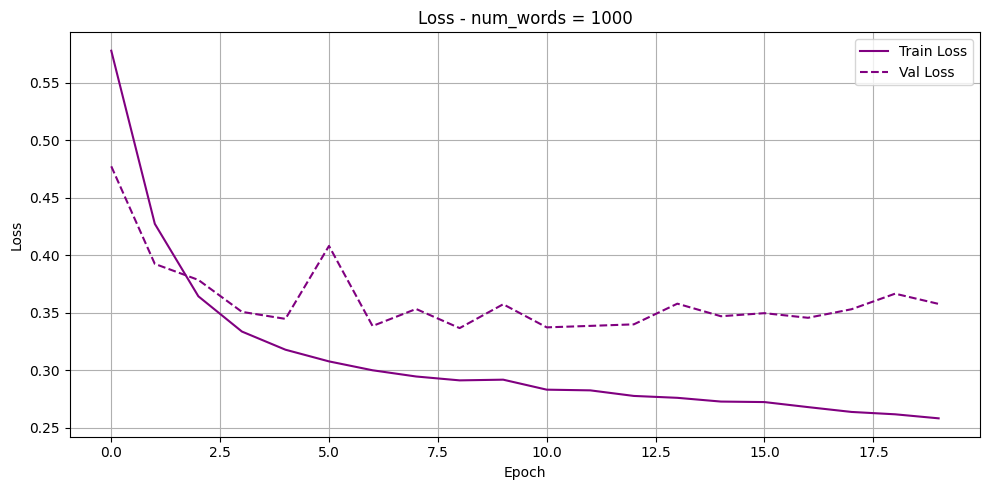

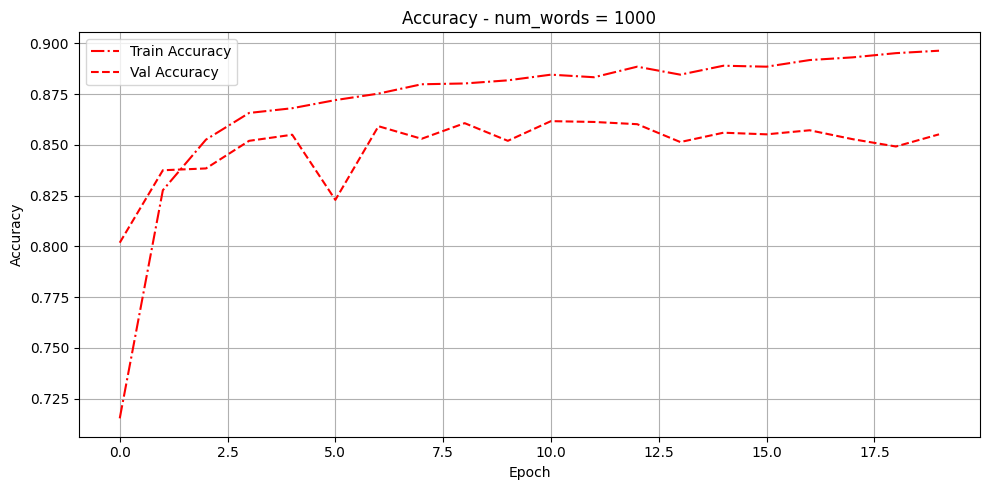

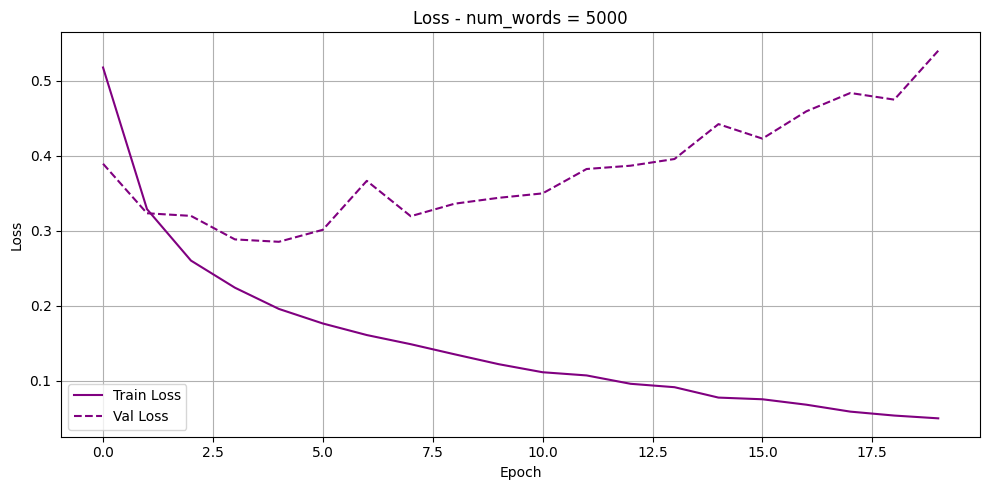

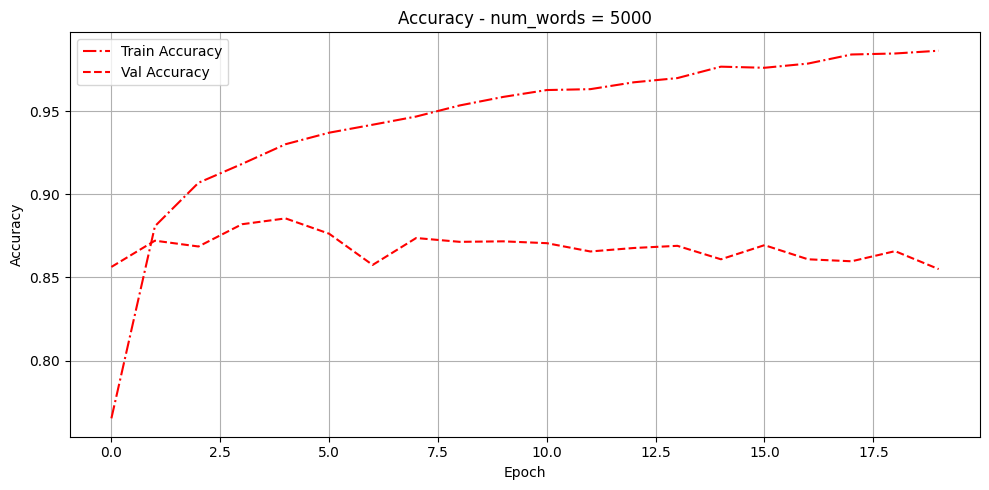

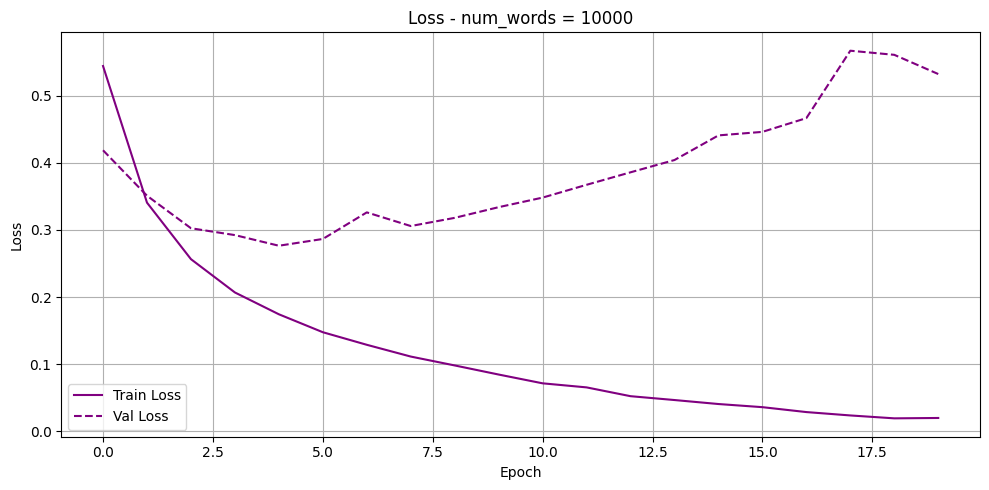

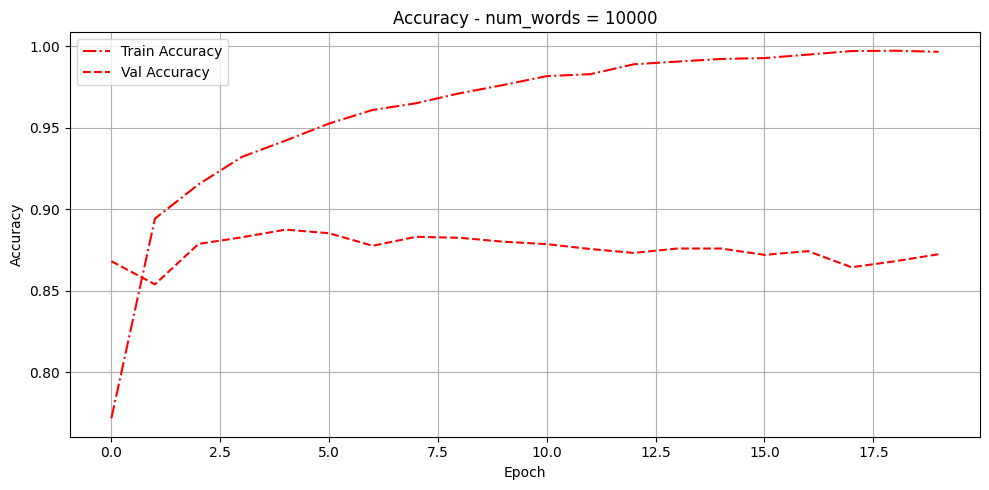

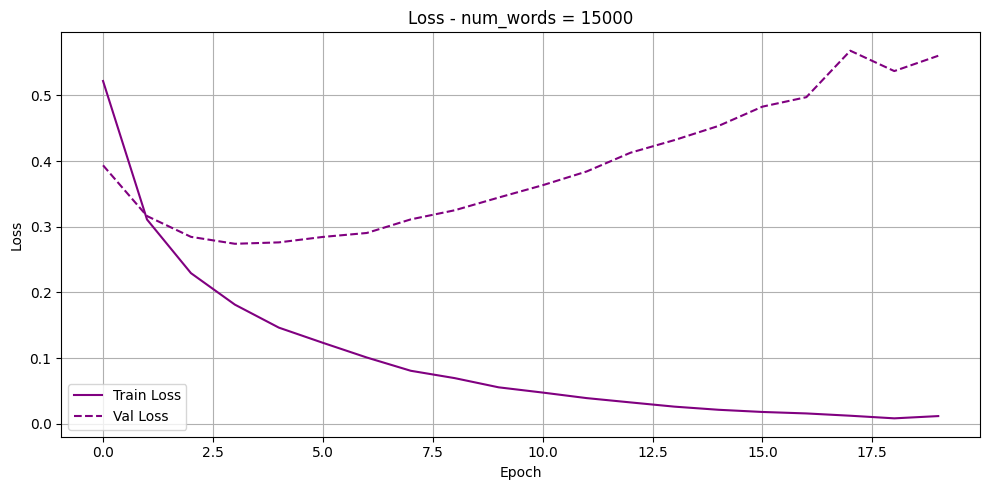

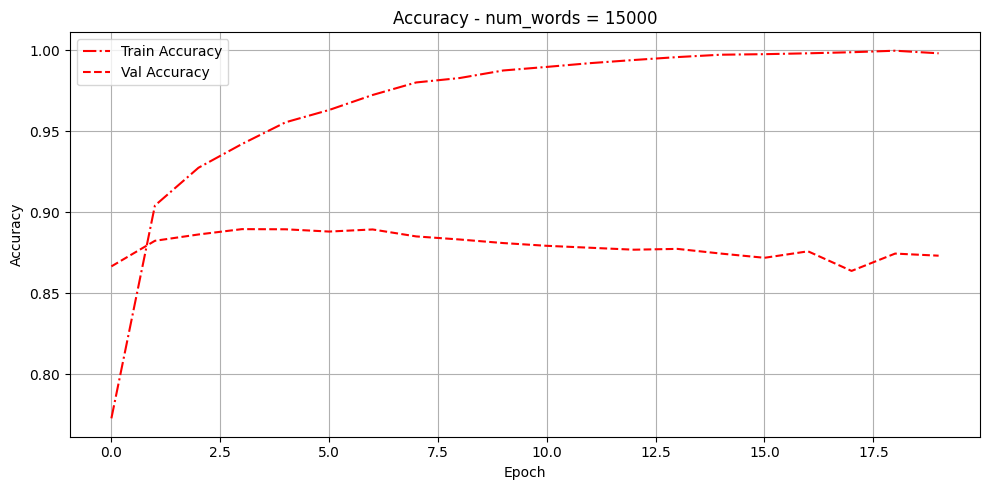

In [11]:
from keras.datasets import imdb
from keras import models
from keras import layers
import numpy as np
from keras import optimizers
from keras import losses
from keras import metrics

word_counts = [1000, 5000, 10000, 15000]
results = {}

def vectorize_sequences(sequences, dimension):
    results = np.zeros((len(sequences), dimension))
    for i, sequence in enumerate(sequences):
        results[i, sequence] = 1.
    return results

def build_model(input_shape):
    model = models.Sequential()
    model.add(layers.Dense(16, activation='relu', input_shape=(input_shape,)))
    model.add(layers.Dense(16, activation='relu'))
    model.add(layers.Dense(1, activation='sigmoid'))
    model.compile(optimizer='rmsprop',
                  loss=losses.binary_crossentropy,
                  metrics=[metrics.binary_accuracy])
    return model

# آموزش برای هر تعداد کلمه
for num_words in word_counts:
    print(f"\nTraining with num_words={num_words}...")
    (train_data, train_labels), (test_data, test_labels) = imdb.load_data(num_words=num_words)
    
    X_train = vectorize_sequences(train_data, num_words)
    X_test = vectorize_sequences(test_data, num_words)
    Y_train = np.asarray(train_labels).astype('float32')
    Y_test = np.asarray(test_labels).astype('float32')
    
    X_val = X_train[:10000]
    partial_X_train = X_train[10000:]
    Y_val = Y_train[:10000]
    partial_Y_train = Y_train[10000:]
    
    model = build_model(num_words)
    history = model.fit(partial_X_train, partial_Y_train,
                        epochs=20,
                        batch_size=512,
                        validation_data=(X_val, Y_val),
                        verbose=0)
    results[num_words] = history.history

# رسم نمودارها
linestyles = {
    'Train Loss': '-',
    'Val Loss': '--',
    'Train Accuracy': '-.',
    'Val Accuracy': '--'
}

for num_words in word_counts:
    history = results[num_words]
    
    # نمودار Loss
    plt.figure(figsize=(10, 5))
    plt.plot(history['loss'], label='Train Loss', color='purple', linestyle=linestyles['Train Loss'])
    plt.plot(history['val_loss'], label='Val Loss', color='purple', linestyle=linestyles['Val Loss'])
    plt.title(f"Loss - num_words = {num_words}")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # نمودار Accuracy
    plt.figure(figsize=(10, 5))
    plt.plot(history['binary_accuracy'], label='Train Accuracy', color='red', linestyle=linestyles['Train Accuracy'])
    plt.plot(history['val_binary_accuracy'], label='Val Accuracy', color='red', linestyle=linestyles['Val Accuracy'])
    plt.title(f"Accuracy - num_words = {num_words}")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

تغییر تعداد لایه ها

Training with 3 hidden layers...
Training with 5 hidden layers...
Training with 7 hidden layers...


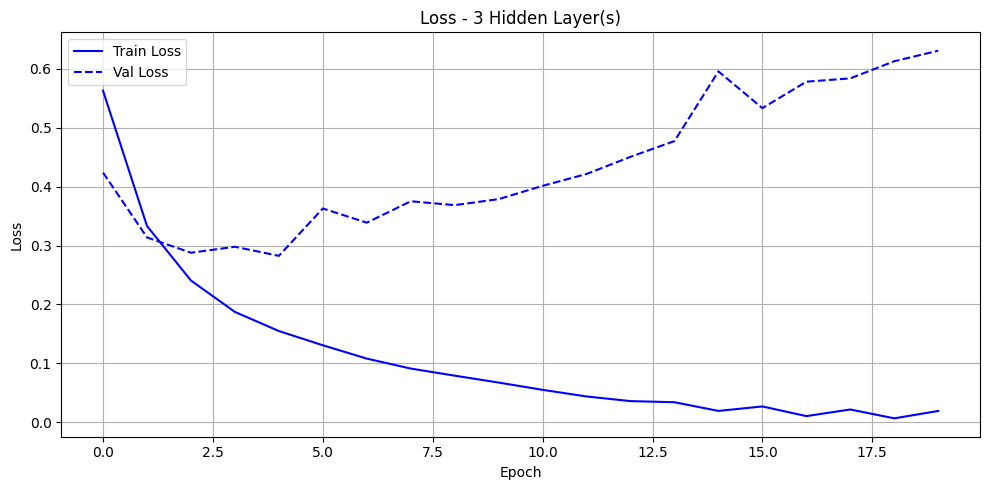

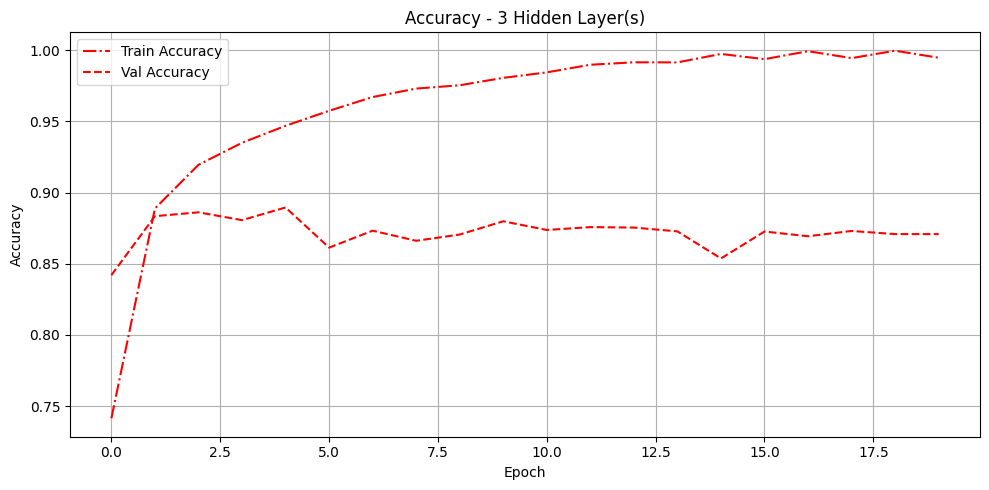

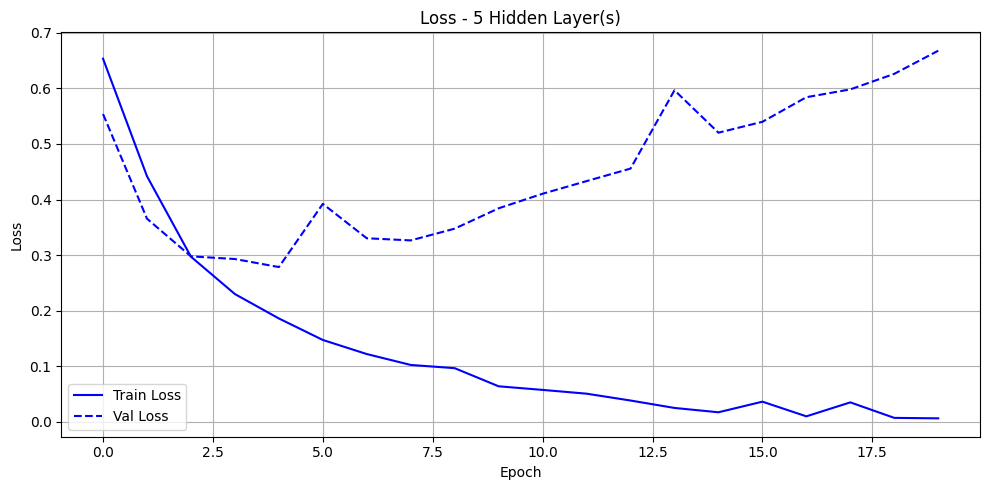

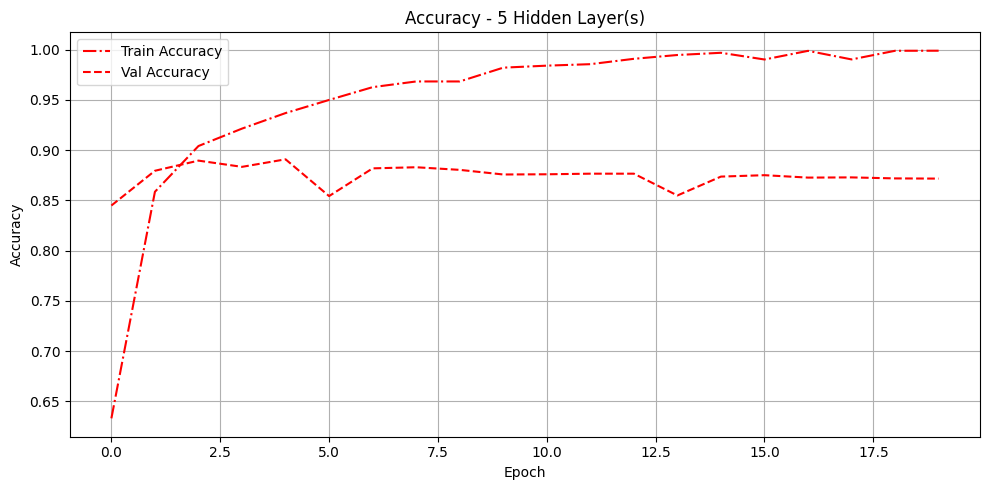

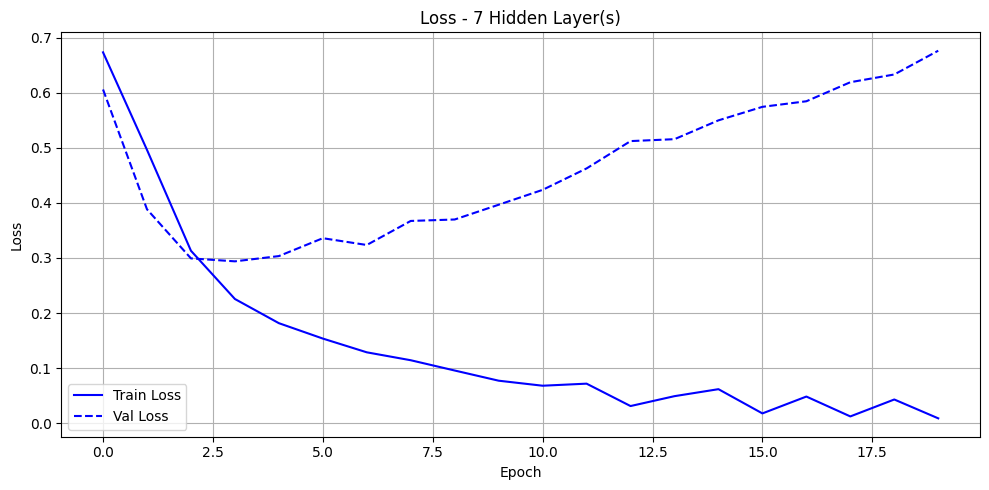

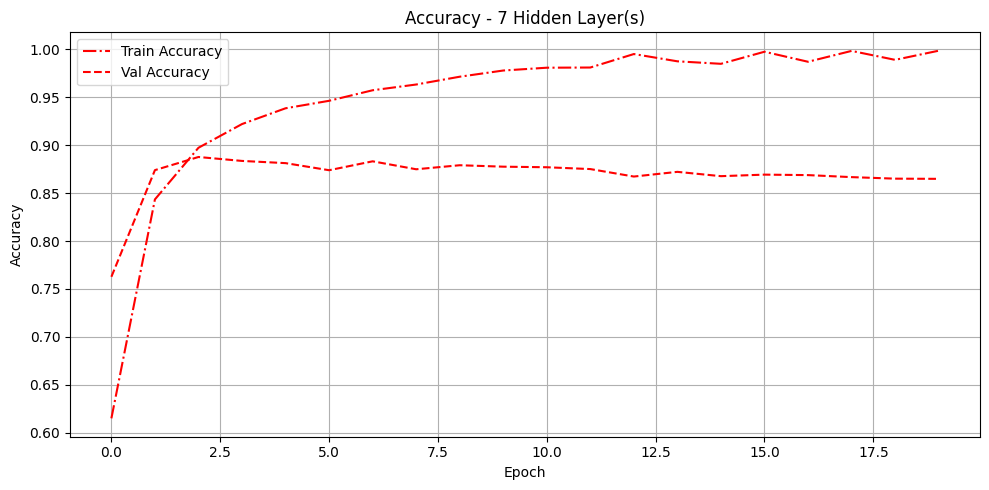

In [12]:
import matplotlib.pyplot as plt
from keras.datasets import imdb
from keras import models
from keras import layers
import numpy as np
from keras import optimizers
from keras import losses
from keras import metrics

# بارگذاری داده‌ها
(train_data, train_labels), (test_data, test_labels) = imdb.load_data(num_words=10000)


# وکتوریزه کردن داده‌ها
def vectorize_sequences(sequences, dimension=10000):
    results = np.zeros((len(sequences), dimension))
    for i, sequence in enumerate(sequences):
        results[i, sequence] = 1.
    return results

X_train = vectorize_sequences(train_data)
X_test = vectorize_sequences(test_data)

# تبدیل لیبل‌ها به نوع داده float32
Y_train = np.asarray(train_labels).astype('float32')
Y_test = np.asarray(test_labels).astype('float32')

# تقسیم داده‌ها به مجموعه آموزش و اعتبارسنجی
X_val = X_train[:10000]
partial_X_train = X_train[10000:]
Y_val = Y_train[:10000]
partial_Y_train = Y_train[10000:]

# تنظیمات تعداد لایه‌های مخفی
layers_config = [3, 5, 7]
history_dict = {}

for num_layers in layers_config:
    print(f"Training with {num_layers} hidden layers...")
    # ساخت مدل
    model = models.Sequential()
    model.add(layers.Dense(16, activation='relu', input_shape=(10000,)))
    for _ in range(num_layers - 1):
        model.add(layers.Dense(16, activation='relu'))
    model.add(layers.Dense(1, activation='sigmoid'))

    # کامپایل مدل
    model.compile(optimizer=optimizers.RMSprop(),
                  loss=losses.binary_crossentropy,
                  metrics=[metrics.binary_accuracy])

    # آموزش مدل
    history = model.fit(partial_X_train, partial_Y_train,
                        epochs=20, batch_size=512,
                        validation_data=(X_val, Y_val),
                        verbose=0)  # خاموش کردن verbose
    
    # ذخیره نتایج برای رسم نمودار
    history_dict[num_layers] = history.history

linestyles = {
    'Train Loss': '-',
    'Val Loss': '--',
    'Train Accuracy': '-.',
    'Val Accuracy': '--'
}

for num_layers, history in history_dict.items():
    # نمودار Loss
    plt.figure(figsize=(10, 5))
    plt.plot(history['loss'], label='Train Loss', color='blue', linestyle=linestyles['Train Loss'])
    plt.plot(history['val_loss'], label='Val Loss', color='blue', linestyle=linestyles['Val Loss'])
    plt.title(f"Loss - {num_layers} Hidden Layer(s)")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # نمودار Accuracy
    plt.figure(figsize=(10, 5))
    plt.plot(history['binary_accuracy'], label='Train Accuracy', color='red', linestyle=linestyles['Train Accuracy'])
    plt.plot(history['val_binary_accuracy'], label='Val Accuracy', color='red', linestyle=linestyles['Val Accuracy'])
    plt.title(f"Accuracy - {num_layers} Hidden Layer(s)")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

تغییر تعداد نورون ها

Training with 16 neurons...
Training with 32 neurons...
Training with 64 neurons...
Training with 128 neurons...
Training with 256 neurons...


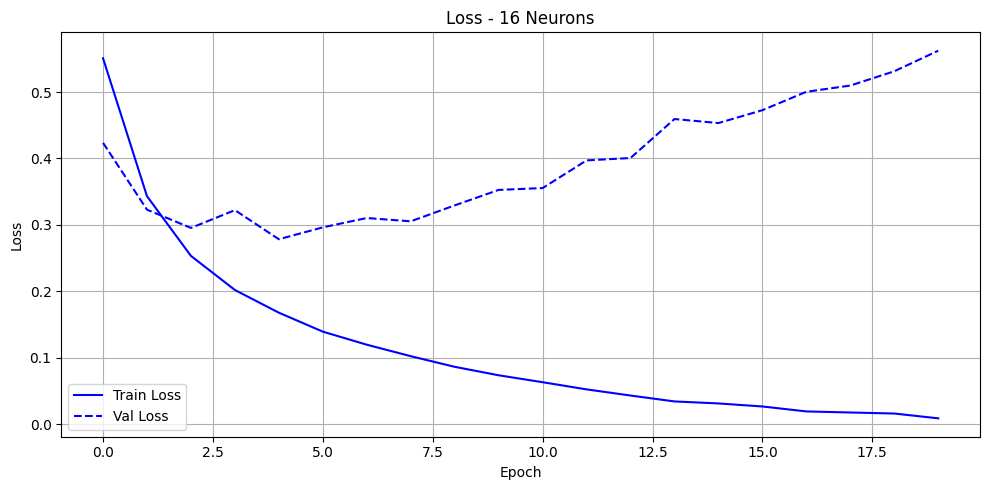

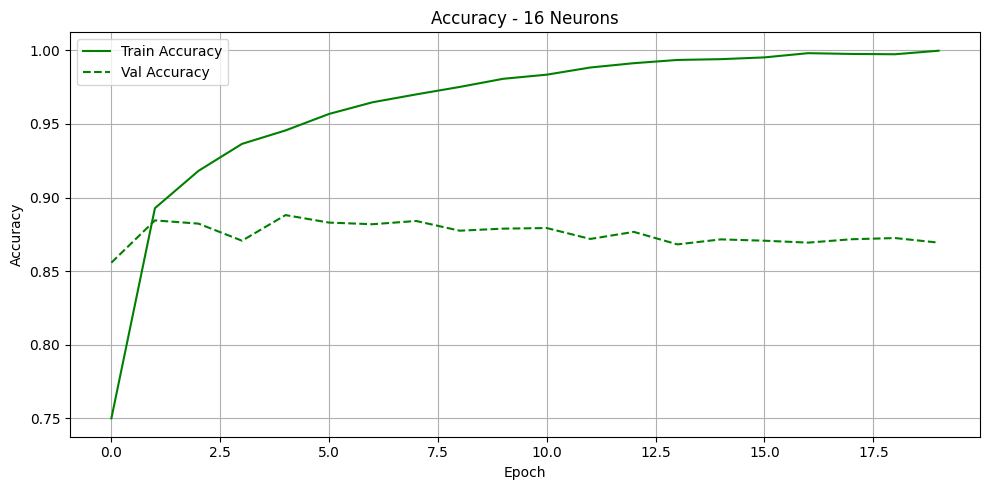

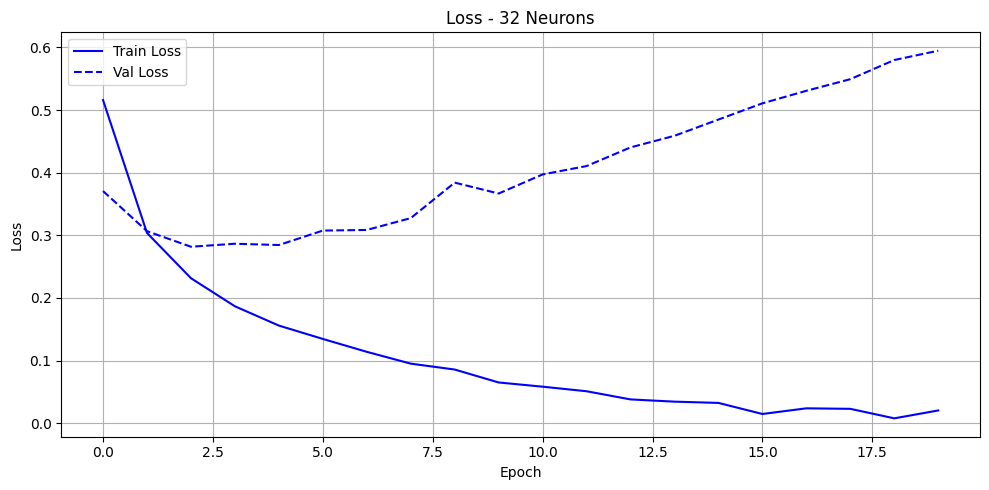

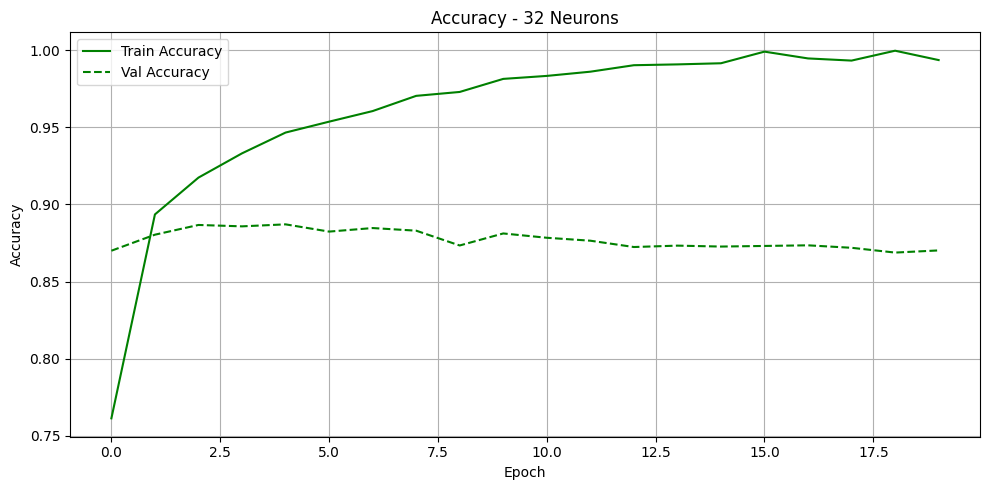

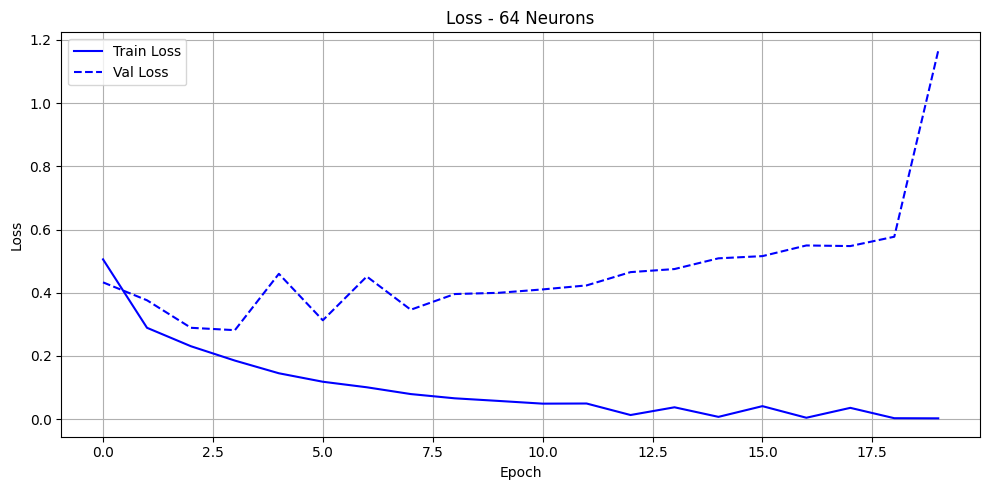

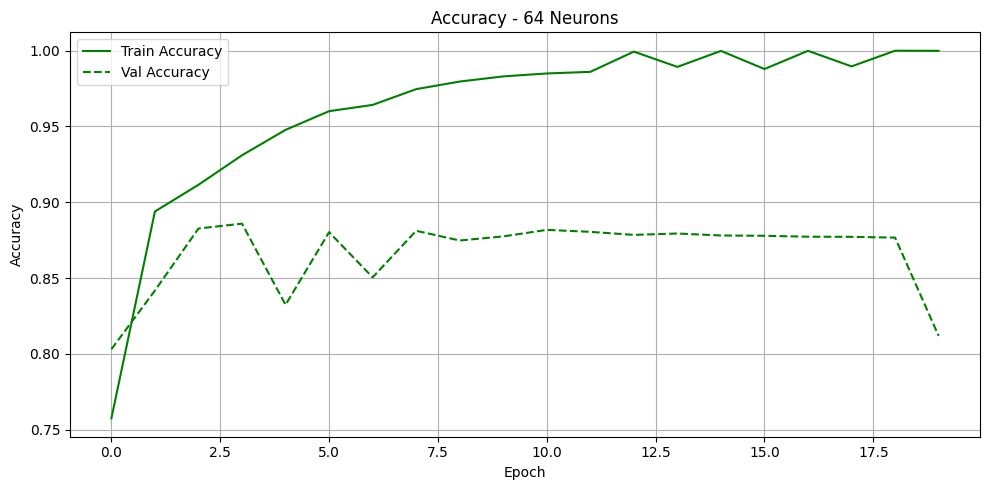

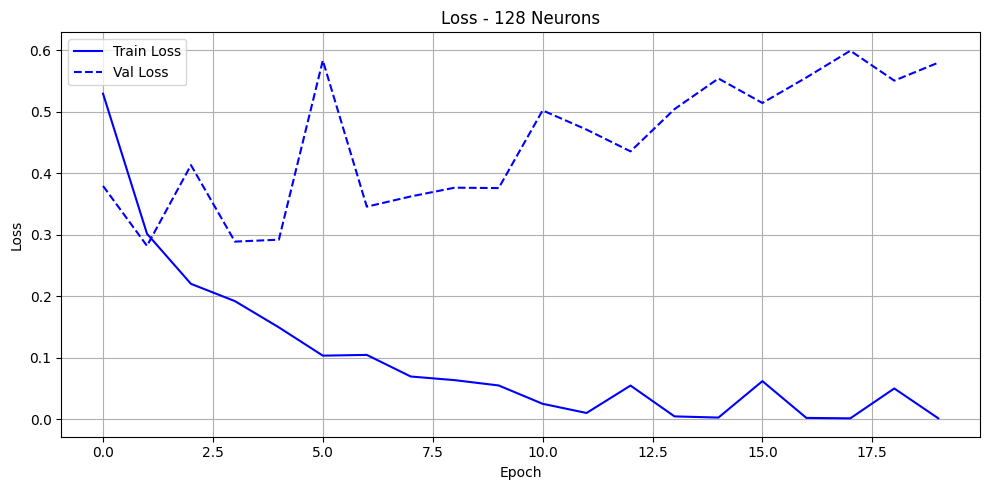

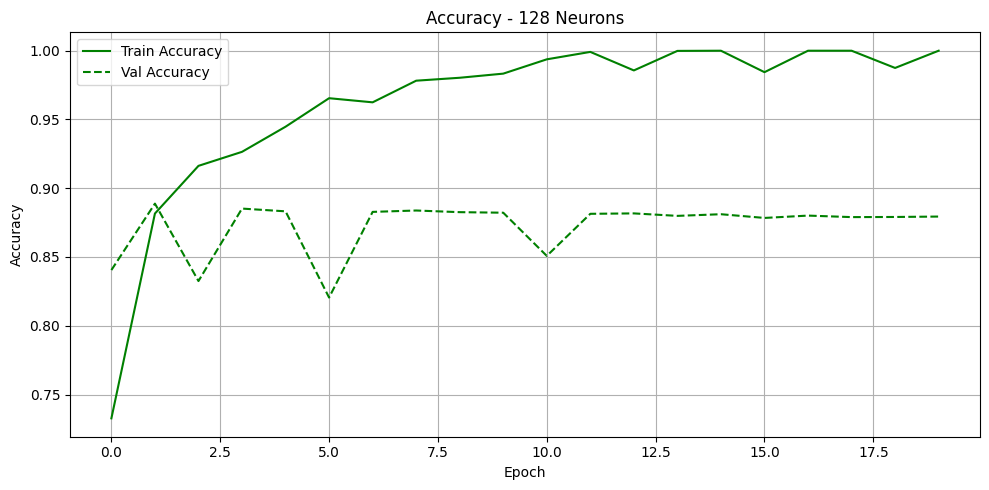

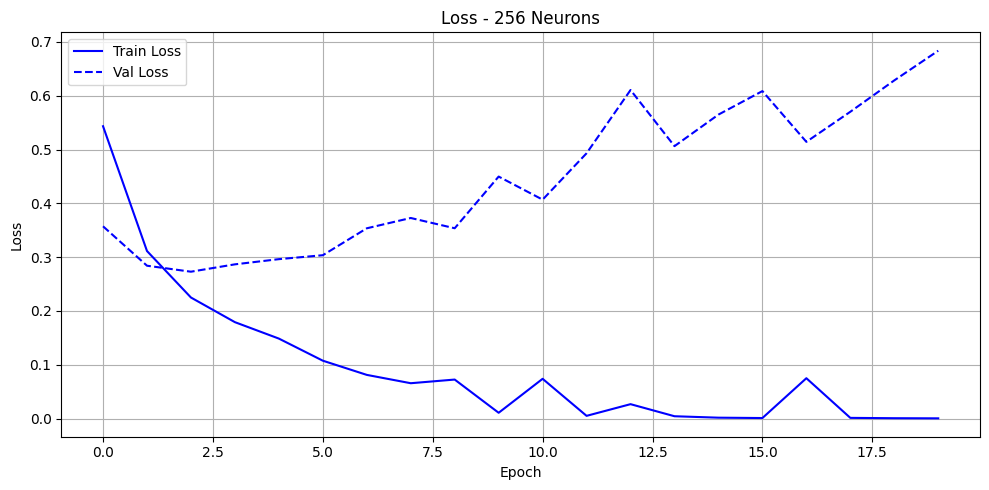

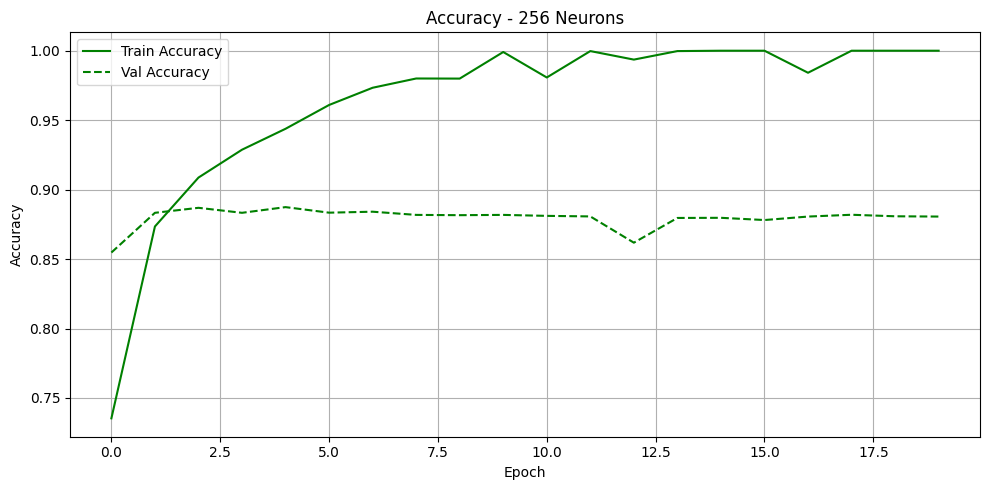

In [14]:
import matplotlib.pyplot as plt
from keras.datasets import imdb
from keras import models
from keras import layers
import numpy as np
from keras import optimizers
from keras import losses
from keras import metrics

# بارگذاری داده‌ها
(train_data, train_labels), (test_data, test_labels) = imdb.load_data(num_words=10000)

# وکتوریزه کردن داده‌ها
def vectorize_sequences(sequences, dimension=10000):
    results = np.zeros((len(sequences), dimension))
    for i, sequence in enumerate(sequences):
        results[i, sequence] = 1.
    return results

X_train = vectorize_sequences(train_data)
X_test = vectorize_sequences(test_data)

# تبدیل لیبل‌ها به نوع داده float32
Y_train = np.asarray(train_labels).astype('float32')
Y_test = np.asarray(test_labels).astype('float32')

# تقسیم داده‌ها به مجموعه آموزش و اعتبارسنجی
X_val = X_train[:10000]
partial_X_train = X_train[10000:]
Y_val = Y_train[:10000]
partial_Y_train = Y_train[10000:]

# تنظیمات تعداد نورون‌ها
neurons_config = [16, 32, 64, 128, 256]
history_dict = {}

for num_neurons in neurons_config:
    print(f"Training with {num_neurons} neurons...")
    # ساخت مدل
    model = models.Sequential()
    model.add(layers.Dense(num_neurons, activation='relu', input_shape=(10000,)))
    model.add(layers.Dense(num_neurons, activation='relu'))
    model.add(layers.Dense(1, activation='sigmoid'))

    # کامپایل مدل
    model.compile(optimizer=optimizers.RMSprop(),
                  loss=losses.binary_crossentropy,
                  metrics=[metrics.binary_accuracy])

    # آموزش مدل
    history = model.fit(partial_X_train, partial_Y_train,
                        epochs=20, batch_size=512,
                        validation_data=(X_val, Y_val),
                        verbose=0)  # خاموش کردن verbose
    
    # ذخیره نتایج برای رسم نمودار
    history_dict[num_neurons] = history.history

linestyles = {
    'Train Loss': '-',
    'Val Loss': '--',
    'Train Accuracy': '-',
    'Val Accuracy': '--'
}

for num_neurons, history in history_dict.items():
    # نمودار Loss
    plt.figure(figsize=(10, 5))
    plt.plot(history['loss'], label='Train Loss', color='blue', linestyle=linestyles['Train Loss'])
    plt.plot(history['val_loss'], label='Val Loss', color='blue', linestyle=linestyles['Val Loss'])
    plt.title(f"Loss - {num_neurons} Neurons")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # نمودار Accuracy
    plt.figure(figsize=(10, 5))
    plt.plot(history['binary_accuracy'], label='Train Accuracy', color='green', linestyle=linestyles['Train Accuracy'])
    plt.plot(history['val_binary_accuracy'], label='Val Accuracy', color='green', linestyle=linestyles['Val Accuracy'])
    plt.title(f"Accuracy - {num_neurons} Neurons")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()